## Curso:

ING200: Optimizacion 

## Sección: 

2

## Profesor:

Jorge Acuña

## Integrantes:

María Fernanda González
Felipe Vicencio
Antonia Herrera 
Matias Leiva 
Esteban Escobar


## Cargado de librerias 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB
from itertools import combinations
from IPython.display import display

## Carga de datos

In [3]:
import datos_festival as datos

Los datos del proyecto se encuentran en el archivo datos_festival.py, que contiene los parámetros oficiales del festival y las funciones auxiliares para calcular la demanda y visualizar las soluciones.

Como los datos están definidos directamente en Python, utilizaremos una importación del módulo en lugar de funciones como pd.read_csv(). El alias datos permitirá identificar claramente el origen de cada variable.

Verificamos que se cargaron correctamente los datos

In [4]:
print("Cantidad de artistas:", len(datos.ARTISTAS))
print("Noches disponibles:", datos.NOCHES)
print("Cantidad de recintos:", len(datos.RECINTOS))

Cantidad de artistas: 15
Noches disponibles: ['Viernes', 'Sábado', 'Domingo']
Cantidad de recintos: 3


Con este resultado concluimos que si se cargaron correctamente los datos

## Organizacion de datos

Aunque los datos están almacenados en diccionarios, resulta conveniente transformarlos en estructuras DataFrame para facilitar su análisis y visualización.

Esta transformación no modifica los datos originales, sino que permite representar ordenadamente las características de los artistas, recintos y noches.

In [5]:
# Tabla de artistas.
df_artistas = pd.DataFrame.from_dict(
    datos.ARTISTAS,
    orient="index"
).rename_axis("Artista").reset_index()

df_artistas = df_artistas.rename(columns={
    "genero": "Género",
    "nivel": "Nivel",
    "popularidad": "Popularidad",
    "costo": "Costo (MM$)",
    "noches": "Disponibilidad"
})

# Tabla de recintos.
df_recintos = pd.DataFrame.from_dict(
    datos.RECINTOS,
    orient="index"
).rename_axis("Recinto").reset_index()

df_recintos = df_recintos.rename(columns={
    "capacidad": "Capacidad (personas)",
    "costo": "Arriendo (MM$)"
})

# Tabla de noches.
df_noches = pd.DataFrame({
    "Noche": datos.NOCHES,
    "Factor de asistencia": [
        datos.FACTOR_NOCHE[n] for n in datos.NOCHES
    ]
})

display(df_artistas)
display(df_recintos)
display(df_noches)

,Artista,Género,Nivel,Popularidad,Costo (MM$),Disponibilidad
0,La Sonora Copihue,Cumbia,G,1.08,52,"[Viernes, Sábado, Domingo]"
1,Los Volcanes,Rock,G,0.97,40,"[Viernes, Sábado, Domingo]"
2,Camila Arrebol,Pop,G,1.03,48,"[Viernes, Sábado, Domingo]"
3,Kevo Flow,Urbano,G,1.12,58,"[Viernes, Sábado]"
4,Los Cumbiancheros del Ñuble,Cumbia,M,0.94,18,"[Viernes, Sábado, Domingo]"
5,Grupo Tierra Sur,Folclor,M,1.06,15,"[Viernes, Sábado, Domingo]"
6,La Nena Real,Urbano,M,1.01,22,"[Viernes, Sábado, Domingo]"
7,Las Hermanas Quintral,Pop,M,0.92,17,"[Viernes, Sábado, Domingo]"
8,Ruta Cinco,Rock,M,1.04,16,"[Viernes, Sábado, Domingo]"
9,Banda Fogata,Cumbia,P,1.11,7,"[Viernes, Sábado, Domingo]"


,Recinto,Capacidad (personas),Arriendo (MM$)
0,Plaza de Armas,12000,30
1,Medialuna,7500,18
2,Gimnasio Municipal,4200,8


,Noche,Factor de asistencia
0,Viernes,0.90
1,Sábado,1.00
2,Domingo,0.85


La información queda organizada en tres tablas: artistas, recintos y noches. Esto facilitará identificar características importantes, como el costo de contratación, la disponibilidad, la capacidad de los recintos y los factores de asistencia.

Estas características serán utilizadas posteriormente para establecer las restricciones y calcular los coeficientes del modelo.

## Distribucion de artistas por nivel y genero

El nivel y el género musical influyen directamente en la demanda del público. Por ello, analizaremos la cantidad de artistas disponibles en cada categoría, lo que permitirá comprender la composición de los candidatos antes de formular el modelo.

Nivel
G    4
M    5
P    6
Name: count, dtype: int64

Género
Cumbia     3
Folclor    3
Pop        3
Rock       3
Urbano     3
Name: count, dtype: int64

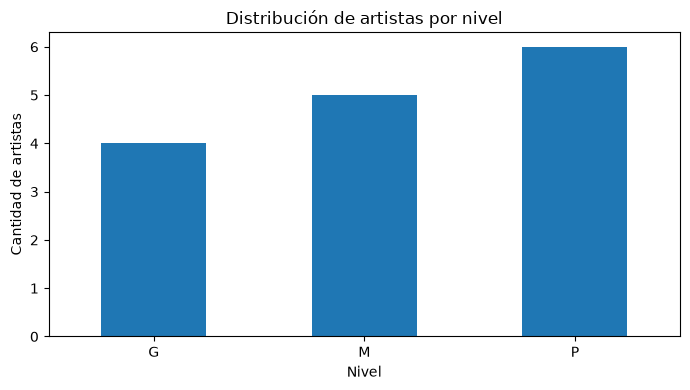

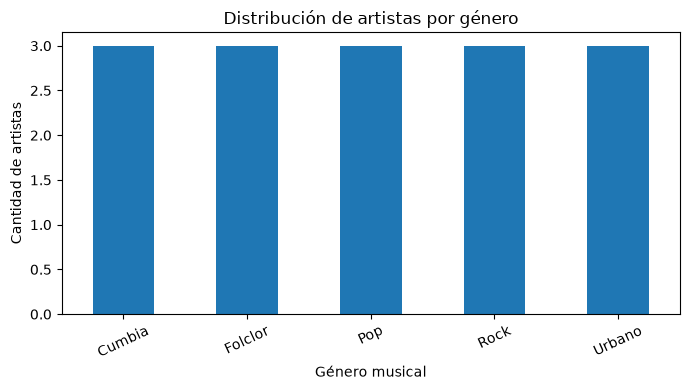

In [6]:
# Contamos artistas por nivel.
nivel = df_artistas["Nivel"].value_counts().reindex(
    ["G", "M", "P"], fill_value=0
)

# Contamos artistas por género.
genero = df_artistas["Género"].value_counts().sort_index()

display(nivel)
display(genero)

# Gráfico de artistas por nivel.
plt.figure(figsize=(7, 4))
nivel.plot(kind="bar")

plt.title("Distribución de artistas por nivel")
plt.xlabel("Nivel")
plt.ylabel("Cantidad de artistas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Gráfico de artistas por género.
plt.figure(figsize=(7, 4))
genero.plot(kind="bar")

plt.title("Distribución de artistas por género")
plt.xlabel("Género musical")
plt.ylabel("Cantidad de artistas")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Se observa que existen 4 artistas grandes, 5 medianos y 6 pequeños, mientras que los cinco géneros musicales cuentan con 3 representantes cada uno.

Esta distribución es relevante porque la demanda depende tanto del nivel de los artistas como de las interacciones entre sus géneros. Sin embargo, no podemos determinar todavía qué combinación resulta más conveniente.

## Análisis de costos de los artistas

El presupuesto disponible es una de las principales restricciones del problema. Por ello, analizaremos los costos de contratación según el nivel de los artistas para identificar sus diferencias y comprender cómo podrían influir en las decisiones de selección.

In [7]:
# Calculamos estadísticas de costos por nivel.
resumen_costos = df_artistas.groupby("Nivel")["Costo (MM$)"].agg(
    cantidad="count",
    costo_minimo="min",
    costo_promedio="mean",
    costo_maximo="max"
)

display(resumen_costos.round(2))

# Ordenamos los artistas desde el más costoso.
display(
    df_artistas[["Artista", "Nivel", "Costo (MM$)"]]
    .sort_values("Costo (MM$)", ascending=False)
)

# Comparamos el costo de todos los artistas
# con el presupuesto disponible.
costo_total = df_artistas["Costo (MM$)"].sum()

print("Costo de todos los artistas:", costo_total, "MM$")
print("Presupuesto disponible:", datos.PRESUPUESTO, "MM$")

,cantidad,costo_minimo,costo_promedio,costo_maximo
Nivel,,,,
G,4,40,49.5,58
M,5,15,17.6,22
P,6,4,6.0,8


,Artista,Nivel,Costo (MM$)
3,Kevo Flow,G,58
0,La Sonora Copihue,G,52
2,Camila Arrebol,G,48
1,Los Volcanes,G,40
6,La Nena Real,M,22
4,Los Cumbiancheros del Ñuble,M,18
7,Las Hermanas Quintral,M,17
8,Ruta Cinco,M,16
5,Grupo Tierra Sur,M,15
13,Tomás del Lago,P,8


Costo de todos los artistas: 322 MM$
Presupuesto disponible: 250 MM$


Contratar a los 15 artistas tendría un costo de 322 MM$, mientras que el presupuesto disponible es de 250 MM$.

Esto evidencia la necesidad de seleccionar cuidadosamente a los artistas, considerando que el presupuesto también debe cubrir el arriendo de los recintos y, cuando corresponda, el plan de seguridad.

## Análisis de disponibilidad

In [8]:
# Contamos los artistas disponibles en cada noche.
disponibles = {
    noche: sum(
        noche in info["noches"]
        for info in datos.ARTISTAS.values()
    )
    for noche in datos.NOCHES
}

df_disponibilidad = pd.DataFrame({
    "Noche": datos.NOCHES,
    "Artistas disponibles": [
        disponibles[n] for n in datos.NOCHES
    ]
})

display(df_disponibilidad)

# Identificamos los artistas no disponibles.
for noche in datos.NOCHES:
    no_disponibles = [
        nombre
        for nombre, info in datos.ARTISTAS.items()
        if noche not in info["noches"]
    ]

    print(f"{noche}: {no_disponibles}")

# Revisamos las condiciones especiales.
print("Teloneros:", datos.TELONEROS)
print("Exclusiones:", datos.EXCLUSIONES)

,Noche,Artistas disponibles
0,Viernes,15
1,Sábado,15
2,Domingo,14


Viernes: []
Sábado: []
Domingo: ['Kevo Flow']
Teloneros: [('La Sonora Copihue', 'Banda Fogata')]
Exclusiones: [('La Nena Real', 'Yisus Beat')]


El viernes y sábado están disponibles los 15 artistas, mientras que el domingo únicamente pueden presentarse 14, debido a la indisponibilidad de Kevo Flow.

Adicionalmente, existen condiciones contractuales que deberán incorporarse al modelo: la presentación conjunta de La Sonora Copihue y Banda Fogata, y la incompatibilidad entre La Nena Real y Yisus Beat.

## Análisis de recinto y factores de asistencia

,Recinto,Capacidad (personas),Arriendo (MM$)
0,Plaza de Armas,12000,30
1,Medialuna,7500,18
2,Gimnasio Municipal,4200,8


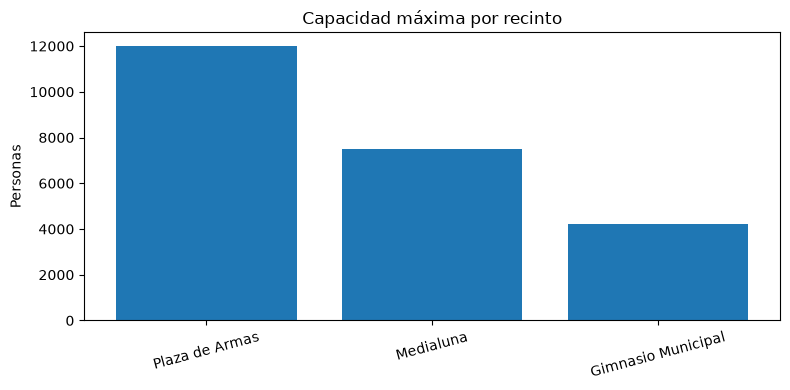

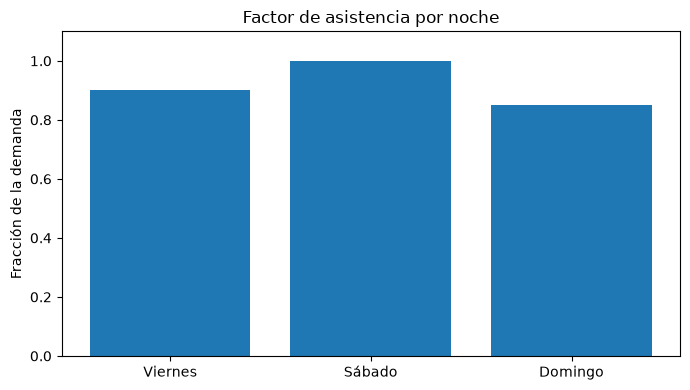

In [9]:
# Mostramos los recintos ordenados por capacidad.
display(
    df_recintos.sort_values(
        "Capacidad (personas)",
        ascending=False
    )
)
# display permite mostrar un dataframe 
# Graficamos las capacidades.
plt.figure(figsize=(8, 4))

plt.bar(
    df_recintos["Recinto"],
    df_recintos["Capacidad (personas)"]
)

plt.title("Capacidad máxima por recinto")
plt.ylabel("Personas")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graficamos los factores de asistencia.
plt.figure(figsize=(7, 4))

plt.bar(
    df_noches["Noche"],
    df_noches["Factor de asistencia"]
)

plt.title("Factor de asistencia por noche")
plt.ylabel("Fracción de la demanda")
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

La Plaza de Armas tiene la mayor capacidad, con 12.000 personas, seguida por la Medialuna con 7.500 y el Gimnasio Municipal con 4.200.

Por otra parte, el sábado presenta el mayor factor de asistencia (1,00), seguido del viernes (0,90) y el domingo (0,85).

Estas diferencias serán importantes porque una misma combinación de artistas puede generar diferentes niveles de público según la noche y el recinto.

## Verificacion de la funcion de demanda 

La demanda no corresponde simplemente a la suma de las demandas individuales. La función oficial incorpora efectos de arrastre e interacciones entre artistas.

Antes de desarrollar el modelo, verificaremos el cálculo utilizando una combinación de ejemplo y evaluando su público esperado en distintos recintos.

In [10]:
# Seleccionamos una combinación de ejemplo.
terna_ejemplo = [
    "Kevo Flow",
    "Ruta Cinco",
    "Banda Fogata"
]

# Calculamos la demanda conjunta.
demanda_conjunta = datos.demanda(terna_ejemplo)

print("Demanda conjunta:", round(demanda_conjunta, 2))

# Calculamos el público esperado por noche y recinto.
resultados = []

for noche in ["Viernes", "Sábado"]:
    for recinto, info in datos.RECINTOS.items():

        publico = round(min(
            datos.FACTOR_NOCHE[noche] * demanda_conjunta,
            info["capacidad"]
        ))

        resultados.append({
            "Noche": noche,
            "Recinto": recinto,
            "Público esperado": publico
        })

df_demanda = pd.DataFrame(resultados)

display(df_demanda)

Demanda conjunta: 9143.39


,Noche,Recinto,Público esperado
0,Viernes,Plaza de Armas,8229
1,Viernes,Medialuna,7500
2,Viernes,Gimnasio Municipal,4200
3,Sábado,Plaza de Armas,9143
4,Sábado,Medialuna,7500
5,Sábado,Gimnasio Municipal,4200


La combinación analizada genera una demanda conjunta de aproximadamente 9.143 personas.

Sin embargo, el público esperado varía según la noche y la capacidad del recinto. Esto confirma que, para maximizar la asistencia total, será necesario considerar conjuntamente la selección de artistas, la asignación de noches y la elección de recintos.

## Validacion de los datos

Finalmente, realizaremos comprobaciones básicas para verificar que los datos utilizados sean consistentes antes de construir las combinaciones y formular el modelo de optimización.

In [11]:
# Validamos la cantidad de elementos.
assert len(datos.ARTISTAS) == 15
assert len(datos.RECINTOS) == 3
assert len(datos.NOCHES) == 3
#assert lo que hace es verificar que una condición sea True, y si no lo es, lanza un error

# Comprobamos los costos y disponibilidades.
for nombre, info in datos.ARTISTAS.items():
    assert info["costo"] >= 0
    assert info["popularidad"] > 0
    assert set(info["noches"]).issubset(set(datos.NOCHES))

# Comprobamos los datos de los recintos.
for recinto, info in datos.RECINTOS.items():
    assert info["capacidad"] > 0
    assert info["costo"] >= 0

print("Validación de datos completada correctamente.")

Validación de datos completada correctamente.


Las comprobaciones permiten verificar que los datos tienen la estructura esperada y contienen valores válidos para los costos, capacidades, popularidades y disponibilidades.

Con esto, disponemos de la información necesaria para comenzar la generación de combinaciones de artistas y la formulación del problema de optimización.

## Generacion de combinaciones artisticas

Como deben presentarse exactamente tres artistas por noche, comenzaremos generando todas las combinaciones posibles de tres artistas mediante itertools.combinations.

Posteriormente, eliminaremos las combinaciones que incumplan las condiciones de disponibilidad y las reglas de contratación entre artistas. Esto permite reducir el número de alternativas que deberá considerar Gurobi.

In [12]:
def terna_admisible(terna):
    # Comprobamos las condiciones entre artistas.
    artistas_terna = set(terna)

    # Si se contrata al artista principal,
    # también debe presentarse su telonero.
    for principal, telonero in datos.TELONEROS:
        if principal in artistas_terna and telonero not in artistas_terna:
            return False

    # Los artistas excluyentes no pueden compartir una terna.
    for artista_a, artista_b in datos.EXCLUSIONES:
        if artista_a in artistas_terna and artista_b in artistas_terna:
            return False

    return True


combinaciones_validas = {}
resumen_combinaciones = []

for noche in datos.NOCHES:

    # Identificamos los artistas disponibles.
    disponibles = [
        artista for artista, info in datos.ARTISTAS.items()
        if noche in info["noches"]
    ]

    # Generamos combinaciones de exactamente tres artistas.
    candidatas = list(combinations(disponibles, 3))

    # Conservamos las combinaciones admisibles.
    validas = [
        terna for terna in candidatas
        if terna_admisible(terna)
    ]

    combinaciones_validas[noche] = validas

    resumen_combinaciones.append({
        "Noche": noche,
        "Artistas disponibles": len(disponibles),
        "Ternas iniciales": len(candidatas),
        "Ternas admisibles": len(validas)
    })

df_combinaciones = pd.DataFrame(resumen_combinaciones)
display(df_combinaciones)

print("Total de ternas admisibles:", sum(len(v) for v in combinaciones_validas.values()))

,Noche,Artistas disponibles,Ternas iniciales,Ternas admisibles
0,Viernes,15,455,365
1,Sábado,15,455,365
2,Domingo,14,364,287


Total de ternas admisibles: 1017


Se obtienen 1.017 ternas admisibles distribuidas entre las tres noches. Sin embargo, todavía debemos incorporar restricciones que afectan al festival completo, como impedir que un artista se presente más de una vez.

## Calculo de demanda , público y costos 

La demanda depende de las características de los artistas y de sus interacciones. Para mantener la linealidad del modelo, calcularemos la demanda y el público esperado de cada alternativa antes de comenzar la optimización.

In [13]:
# Calculamos una sola vez la demanda de cada terna distinta.
ternas_distintas = set().union(*[
    set(ternas) for ternas in combinaciones_validas.values()
])

demanda_por_terna = {
    terna: datos.demanda(terna)
    for terna in ternas_distintas
}

alternativas = []

for noche in datos.NOCHES:
    for terna in combinaciones_validas[noche]:

        demanda_terna = demanda_por_terna[terna]

        costo_artistas = sum(
            datos.ARTISTAS[a]["costo"] for a in terna
        )

        for recinto, info in datos.RECINTOS.items():

            # Demanda ajustada por noche y capacidad.
            publico = round(min(
                datos.FACTOR_NOCHE[noche] * demanda_terna,
                info["capacidad"]
            ))

            # Guardamos los parámetros de cada alternativa.
            alternativas.append({
                "id": len(alternativas),
                "noche": noche,
                "recinto": recinto,
                "terna": terna,
                "demanda": demanda_terna,
                "publico": publico,
                "costo": costo_artistas + info["costo"]
            })

df_alternativas = pd.DataFrame(alternativas)

display(df_alternativas.head())
print("Total de alternativas:", len(alternativas))

,id,noche,recinto,terna,demanda,publico,costo
0,0,Viernes,Plaza de Armas,"(La Sonora Copihue, Los Volcanes, Banda Fogata)",7884.225,7096,129
1,1,Viernes,Medialuna,"(La Sonora Copihue, Los Volcanes, Banda Fogata)",7884.225,7096,117
2,2,Viernes,Gimnasio Municipal,"(La Sonora Copihue, Los Volcanes, Banda Fogata)",7884.225,4200,107
3,3,Viernes,Plaza de Armas,"(La Sonora Copihue, Camila Arrebol, Banda Fogata)",8226.000,7403,137
4,4,Viernes,Medialuna,"(La Sonora Copihue, Camila Arrebol, Banda Fogata)",8226.000,7403,125


Total de alternativas: 3051


Se generan 3.051 alternativas posibles considerando ternas, noches y recintos.

Cada alternativa contiene un público esperado y un costo previamente calculados. Esto permitirá utilizar dichos valores como constantes dentro del modelo de programación lineal entera.

## Conjuntos, parámetros y variables de decisión

Para representar las decisiones de la municipalidad, se definirán los conjuntos de artistas, noches, recintos y alternativas disponibles. Además, se utilizarán variables binarias que indicarán si una determinada combinación de artistas, noche y recinto es seleccionada. También se incorporará una variable que permita determinar si corresponde contratar el plan de seguridad. Estas variables permitirán representar las decisiones necesarias para organizar el festival.

In [14]:
# Definimos los conjuntos del modelo.
A = list(datos.ARTISTAS.keys())
N = datos.NOCHES
R = list(datos.RECINTOS.keys())
I = range(len(alternativas))

# Identificamos las alternativas de cada noche.
indices_por_noche = {
    noche: [
        i for i, alt in enumerate(alternativas)
        if alt["noche"] == noche
    ]
    for noche in N
}

# Identificamos las alternativas que incluyen cada artista.
indices_por_artista = {
    artista: [
        i for i, alt in enumerate(alternativas)
        if artista in alt["terna"]
    ]
    for artista in A
}

# Definimos una función para crear las variables binarias.
def crear_variables(modelo):

    # Selección de una alternativa de programación.
    x = modelo.addVars(
        I,
        vtype=GRB.BINARY,
        name="x"
    )

    # Contratación del plan de seguridad.
    seguridad = modelo.addVar(
        vtype=GRB.BINARY,
        name="plan_seguridad"
    )

    return x, seguridad

Se establecieron los conjuntos correspondientes a artistas, noches, recintos y alternativas de programación.

Adicionalmente, se definió una función que permitirá incorporar al modelo las variables binarias necesarias. Estas representarán la selección de alternativas y la contratación del plan de seguridad.

Las variables se crearán efectivamente cuando llamemos a crear_variables() dentro de la construcción del modelo.

## Función objetivo y restricciones

El modelo tendrá como objetivo maximizar el público total esperado durante las tres noches del festival. Para ello, se utilizarán los valores de asistencia previamente calculados para cada alternativa. Además, se incorporarán restricciones que aseguren la selección de exactamente tres artistas por noche, eviten la repetición de artistas, respeten las condiciones de contratación y garanticen el cumplimiento del presupuesto disponible. También se considerará la activación del plan de seguridad cuando la asistencia total supere el límite establecido.

In [ ]:
def agregar_objetivo_y_restricciones(modelo, x, seguridad, presupuesto):

    # Calculamos el público total esperado.
    publico_total = gp.quicksum(
        alt["publico"] * x[i]
        for i, alt in enumerate(alternativas)
    )

    # Calculamos el costo total del festival.
    costo_total = (
        gp.quicksum(
            alt["costo"] * x[i]
            for i, alt in enumerate(alternativas)
        )
        + datos.COSTO_SEGURIDAD * seguridad
    )

    # FUNCIÓN OBJETIVO:
    # Maximizar el público total esperado.
    modelo.setObjective(
        publico_total,
        GRB.MAXIMIZE
    )

    # R1: Seleccionar exactamente una alternativa por noche.
    for j, noche in enumerate(N):
        modelo.addConstr(
            gp.quicksum(
                x[i] for i in indices_por_noche[noche]
            ) == 1,
            name=f"noche_{j}"
        )

    # R2: Cada artista se presenta como máximo una vez.
    for j, artista in enumerate(A):
        modelo.addConstr(
            gp.quicksum(
                x[i] for i in indices_por_artista[artista]
            ) <= 1,
            name=f"artista_{j}"
        )

    # R3: Disponibilidad y teloneros.
    # Estas condiciones ya se verificaron en la sección 2.1.

    # R4: No contratar artistas incompatibles.
    for j, (artista_a, artista_b) in enumerate(datos.EXCLUSIONES):
        modelo.addConstr(
            gp.quicksum(
                x[i] for i in indices_por_artista[artista_a]
            )
            + gp.quicksum(
                x[i] for i in indices_por_artista[artista_b]
            ) <= 1,
            name=f"exclusion_{j}"
        )

    # R5: Respetar el presupuesto total.
    modelo.addConstr(
        costo_total <= presupuesto,
        name="presupuesto"
    )

    # R6: Activar el plan de seguridad cuando corresponda.
    umbral = datos.UMBRAL_SEGURIDAD

    # Calculamos el máximo público posible por capacidad.
    maximo_publico = len(N) * max(
        info["capacidad"]
        for info in datos.RECINTOS.values()
    )

    # Definimos Big-M a partir del límite máximo de público.
    M = maximo_publico - umbral

    modelo.addConstr(
        publico_total <= umbral + M * seguridad,
        name="activar_seguridad"
    )

    modelo.addConstr(
        publico_total >= (umbral + 1) * seguridad,
        name="condicion_seguridad"
    )

    return publico_total, costo_total

Se incorporó la función objetivo de maximización del público y las restricciones del festival.

Las restricciones de seguridad permiten activar el plan únicamente cuando el público supera las 20.000 personas. Para ello se utilizó un valor Big-M de 16.000, calculado a partir del máximo público posible por capacidad.

Debido a que los valores de demanda y costos se calcularon previamente, la función objetivo y las restricciones están compuestas por expresiones lineales.

## Construcción del modelo en Gurobi

Una vez definidas las variables, la función objetivo y las restricciones, construiremos el modelo completo.

Para facilitar las siguientes etapas, utilizaremos una función reutilizable que permita modificar el presupuesto sin volver a escribir toda la formulación.

In [16]:
def construir_modelo(presupuesto=datos.PRESUPUESTO):

    # Creamos el modelo de optimización.
    modelo = gp.Model("Festival_Villa_Peumayen")

    # Establecemos una brecha de optimalidad nula.
    modelo.Params.MIPGap = 0

    # Incorporamos las variables binarias de la sección 2.3.
    x, seguridad = crear_variables(modelo)

    # Incorporamos el objetivo y restricciones de la sección 2.4.
    publico_total, costo_total = agregar_objetivo_y_restricciones(
        modelo,
        x,
        seguridad,
        presupuesto
    )

    # Actualizamos el modelo.
    modelo.update()

    return modelo, x, seguridad, publico_total, costo_total

Se construyó una función que permite generar el modelo de programación lineal entera, incluyendo sus variables de decisión, función objetivo y restricciones.

La función recibe el presupuesto como parámetro, lo cual permitirá reutilizarla posteriormente para estudiar los escenarios presupuestarios solicitados en la pregunta (d).

En esta etapa todavía no ejecutamos la optimización.

## Validación del modelo

Antes de resolver el modelo, verificaremos que las alternativas generadas cumplan las condiciones iniciales y que Gurobi haya construido correctamente las variables y restricciones.

Esta validación permitirá detectar errores de formulación antes de ejecutar el optimizador.

In [17]:
# Verificamos la cantidad total de alternativas.
assert len(alternativas) == sum(
    len(ternas) for ternas in combinaciones_validas.values()
) * len(datos.RECINTOS)

# Verificamos que cada alternativa tenga tres artistas distintos.
assert all(
    len(set(alt["terna"])) == 3
    for alt in alternativas
)

# Comprobamos las condiciones de contratación.
assert all(
    terna_admisible(alt["terna"])
    for alt in alternativas
)

# Comprobamos la disponibilidad de los artistas.
assert all(
    alt["noche"] in datos.ARTISTAS[a]["noches"]
    for alt in alternativas
    for a in alt["terna"]
)

# Comprobamos que el público no supere la capacidad.
assert all(
    0 <= alt["publico"]
    <= datos.RECINTOS[alt["recinto"]]["capacidad"]
    for alt in alternativas
)

# Construimos el modelo con el presupuesto original.
modelo_base, x_base, s_base, z_base, costo_base = construir_modelo(
    presupuesto=datos.PRESUPUESTO
)

# Mostramos la estructura del modelo.
print("Modelo:", modelo_base.ModelName)
print("Variables:", modelo_base.NumVars)
print("Restricciones:", modelo_base.NumConstrs)
print("Presupuesto:", datos.PRESUPUESTO, "MM$")

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2835554
Academic license 2835554 - for non-commercial use only - registered to le___@gmail.com
Set parameter MIPGap to value 0
Modelo: Festival_Villa_Peumayen
Variables: 3052
Restricciones: 22
Presupuesto: 250 MM$


El modelo contiene 3.052 variables binarias: 3.051 corresponden a alternativas de programación y una representa la contratación del plan de seguridad.

Además, incluye 22 restricciones lineales que permiten representar las condiciones globales del festival. Las restricciones de disponibilidad y teloneros se incorporaron mediante la generación previa de ternas admisibles.

Con esto se ha completado la construcción del modelo, quedando preparado para su resolución computacional.

## Resolución inicial del modelo

Para determinar la situación base del festival, resolveremos el modelo construido anteriormente utilizando el presupuesto original de la municipalidad. Para ello, emplearemos Gurobi y estableceremos una brecha de optimalidad nula, asegurando que el optimizador no se detenga únicamente por cumplir una tolerancia de optimalidad positiva. Posteriormente, verificaremos el estado de la solución para confirmar que el modelo se resolvió correctamente.

In [18]:
# Construimos el modelo con el presupuesto original.
modelo_max, x_max, seguridad_max, z_max, costo_max = construir_modelo(
    presupuesto=datos.PRESUPUESTO
)

# Exigimos una brecha de optimalidad nula.
modelo_max.Params.MIPGap = 0

# Resolvemos el modelo de maximización.
modelo_max.optimize()

# Verificamos que se alcanzó la solución óptima.
if modelo_max.Status != GRB.OPTIMAL:
    raise RuntimeError("No se encontró una solución óptima.")

# Guardamos el máximo público esperado.
publico_optimo = int(round(z_max.getValue()))

print("Público máximo esperado:", publico_optimo)

Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Fedora Linux 44 (KDE Plasma Desktop Edition)")

CPU model: AMD Ryzen 5 7535HS with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
MIPGap  0

Academic license 2835554 - for non-commercial use only - registered to le___@gmail.com
Optimize a model with 22 rows, 3052 columns and 22500 nonzeros (Max)
Model fingerprint: 0x528f2031
Model has 3051 linear objective coefficients
Variable types: 0 continuous, 3052 integer (3052 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+04]
  Objective range  [1e+03, 1e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Found heuristic solution: objective 17121.000000
Presolve removed 3 rows and 1362 columns
Presolve time: 0.03s
Presolved: 19 rows, 1690 columns, 11738 nonzeros
Found heuristic solu

La resolución permite identificar la máxima cantidad de asistentes que puede atraer el festival respetando las condiciones establecidas. Este valor representa el objetivo principal de la municipalidad y se utilizará en la siguiente etapa para seleccionar la alternativa de menor costo sin reducir la asistencia.

## Selección de la solución de menor costo

El enunciado establece que, cuando existan distintas soluciones que alcancen el mismo público máximo, debe seleccionarse aquella que tenga el menor costo total. Para cumplir este criterio, realizaremos una segunda optimización en la que mantendremos fija la asistencia máxima obtenida anteriormente y minimizaremos el gasto asociado a artistas, recintos y seguridad.

Este procedimiento permite cumplir ambos objetivos de manera ordenada, priorizando la asistencia del festival por sobre el ahorro presupuestario.

In [19]:
# Construimos nuevamente el modelo.
modelo_min, x_min, seguridad_min, z_min, costo_min = construir_modelo(
    presupuesto=datos.PRESUPUESTO
)

# Exigimos mantener el público máximo obtenido.
modelo_min.addConstr(
    z_min == publico_optimo,
    name="mantener_publico_optimo"
)

# Modificamos el objetivo para minimizar el costo.
modelo_min.setObjective(
    costo_min,
    GRB.MINIMIZE
)

# Exigimos optimalidad exacta.
modelo_min.Params.MIPGap = 0

# Resolvemos el segundo modelo.
modelo_min.optimize()

# Verificamos la solución.
if modelo_min.Status != GRB.OPTIMAL:
    raise RuntimeError("No se encontró una solución óptima.")

# Guardamos los resultados definitivos.
publico_total_optimo = int(round(z_min.getValue()))
costo_total_optimo = int(round(costo_min.getValue()))
seguridad_contratada = int(round(seguridad_min.X))

print("Público total:", publico_total_optimo)
print("Costo mínimo:", costo_total_optimo, "MM$")
print("Plan de seguridad:", "Sí" if seguridad_contratada else "No")

Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Fedora Linux 44 (KDE Plasma Desktop Edition)")

CPU model: AMD Ryzen 5 7535HS with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
MIPGap  0

Academic license 2835554 - for non-commercial use only - registered to le___@gmail.com
Optimize a model with 23 rows, 3052 columns and 25551 nonzeros (Min)
Model fingerprint: 0x3a1fda4a
Model has 3052 linear objective coefficients
Variable types: 0 continuous, 3052 integer (3052 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+04]
  Objective range  [2e+01, 2e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Presolve removed 5 rows and 1363 columns
Presolve time: 0.03s
Presolved: 18 rows, 1689 columns, 10047 nonzeros
Variable types: 0 continuous, 1689 integer (1689 binary)

Root relaxa

La segunda optimización permitió obtener un público máximo esperado de 19.999 personas, con un costo mínimo de 249 MM$. Esto representa una utilización del 99,6 % del presupuesto disponible, dejando un saldo de 1 MM$.

Además, debido a que la asistencia esperada no supera el umbral de 20.000 personas, no es necesario contratar el plan de seguridad adicional. Por lo tanto, la solución obtenida cumple con los objetivos de maximizar la asistencia y minimizar el costo entre las alternativas que alcanzan dicho máximo.

## Extracción de la parrilla óptima

Una vez obtenida la solución óptima, identificaremos las alternativas seleccionadas por Gurobi. A partir de estas decisiones construiremos una tabla que presente los artistas contratados, el recinto utilizado, el público esperado y el costo de cada noche. Esto permitirá interpretar los resultados del modelo y responder directamente a los requerimientos del enunciado.

In [20]:
# Identificamos las alternativas seleccionadas.
seleccionadas = [
    alt for alt in alternativas
    if x_min[alt["id"]].X > 0.5
]

# Ordenamos las alternativas por noche.
orden_noches = {
    noche: i
    for i, noche in enumerate(datos.NOCHES)
}

seleccionadas.sort(
    key=lambda alt: orden_noches[alt["noche"]]
)

# Construimos una tabla con la solución.
df_solucion = pd.DataFrame([
    {
        "Noche": alt["noche"],
        "Recinto": alt["recinto"],
        "Artistas": ", ".join(alt["terna"]),
        "Público esperado": alt["publico"],
        "Costo (MM$)": alt["costo"]
    }
    for alt in seleccionadas
])

display(df_solucion)

,Noche,Recinto,Artistas,Público esperado,Costo (MM$)
0,Viernes,Plaza de Armas,"Kevo Flow, Los Cumbiancheros del Ñuble, Las He...",9657,123
1,Sábado,Medialuna,"Camila Arrebol, Grupo Tierra Sur, Niebla Austral",7045,87
2,Domingo,Gimnasio Municipal,"Ruta Cinco, Banda Fogata, Tomás del Lago",3297,39


La solución óptima distribuye los artistas y recintos de manera que se maximice la asistencia total del festival. El viernes presenta la mayor convocatoria, con 9.657 personas en la Plaza de Armas, seguido del sábado con 7.045 personas en la Medialuna y el domingo con 3.297 personas en el Gimnasio Municipal.

Esta distribución responde a las diferencias de demanda entre las combinaciones de artistas, los factores de asistencia de cada noche y las capacidades de los recintos. En conjunto, se alcanza un público esperado de 19.999 personas con un costo total de 249 MM$, respetando el presupuesto disponible.

## Validación de la solución y resumen de costos

Para comprobar que la solución obtenida cumple las condiciones del problema, verificaremos que cada noche tenga exactamente tres artistas, que ninguno se presente más de una vez y que se respeten las condiciones de disponibilidad y contratación.

También comprobaremos que el costo total no supere el presupuesto y que el plan de seguridad se active únicamente cuando corresponda.

In [21]:
# Verificamos que exista una alternativa por noche.
assert len(seleccionadas) == len(datos.NOCHES)

# Reunimos los artistas seleccionados.
artistas_elegidos = [
    artista
    for alt in seleccionadas
    for artista in alt["terna"]
]

# Comprobamos que cada noche tenga exactamente tres artistas.
assert all(
    len(alt["terna"]) == 3
    for alt in seleccionadas
)

# Comprobamos que ningún artista se repita.
assert len(artistas_elegidos) == len(set(artistas_elegidos))

# Comprobamos las condiciones de contratación.
for principal, telonero in datos.TELONEROS:
    if principal in artistas_elegidos:
        assert any(
            principal in alt["terna"] and telonero in alt["terna"]
            for alt in seleccionadas
        )

for artista_a, artista_b in datos.EXCLUSIONES:
    assert not (
        artista_a in artistas_elegidos
        and artista_b in artistas_elegidos
    )

# Calculamos el desglose de los costos.
costo_sin_seguridad = sum(
    alt["costo"] for alt in seleccionadas
)

costo_seguridad = (
    datos.COSTO_SEGURIDAD * seguridad_contratada
)

# Verificamos el presupuesto y la condición de seguridad.
assert costo_total_optimo <= datos.PRESUPUESTO

assert bool(seguridad_contratada) == (
    publico_total_optimo > datos.UMBRAL_SEGURIDAD
)

# Guardamos la situación base para las siguientes preguntas.
solucion_base = {
    "presupuesto": datos.PRESUPUESTO,
    "publico_total": publico_total_optimo,
    "costo_total": costo_total_optimo,
    "seguridad": bool(seguridad_contratada),
    "seleccionadas": seleccionadas
}

# Presentamos los resultados generales.
print("Público total:", publico_total_optimo)
print("Costo artistas y recintos:", costo_sin_seguridad, "MM$")
print("Costo seguridad:", costo_seguridad, "MM$")
print("Costo total:", costo_total_optimo, "MM$")
print("Presupuesto restante:",
      datos.PRESUPUESTO - costo_total_optimo, "MM$")

Público total: 19999
Costo artistas y recintos: 249 MM$
Costo seguridad: 0 MM$
Costo total: 249 MM$
Presupuesto restante: 1 MM$


La validación confirma que la solución obtenida cumple con las restricciones del modelo. El festival alcanza una asistencia esperada de 19.999 personas, con un costo total de 249 MM$, equivalente al 99,6 % del presupuesto disponible.

Debido a que el público esperado no supera las 20.000 personas, no se requiere contratar el plan de seguridad, cuyo costo adicional sería de 25 MM$. Finalmente, la municipalidad dispone de un saldo presupuestario de 1 MM$, manteniendo la máxima asistencia posible bajo las condiciones establecidas.

## Visualización de la solución óptima

Para facilitar la presentación e interpretación de los resultados, utilizaremos la función de visualización proporcionada en los datos oficiales. Esta permitirá representar la asistencia esperada por noche e identificar los recintos seleccionados.

Situación base: parrilla óptima del festival
----------------------------------------------------------------------------------------------------
Viernes  | Plaza de Armas     |  9,657 personas |  123 MM$ | Kevo Flow (G), Los Cumbiancheros del Ñuble (M), Las Hermanas Quintral (M)
Sábado   | Medialuna          |  7,045 personas |   87 MM$ | Camila Arrebol (G), Grupo Tierra Sur (M), Niebla Austral (P)
Domingo  | Gimnasio Municipal |  3,297 personas |   39 MM$ | Ruta Cinco (M), Banda Fogata (P), Tomás del Lago (P)
----------------------------------------------------------------------------------------------------
Total: 19,999 personas | 249 MM$ (sin plan de seguridad)


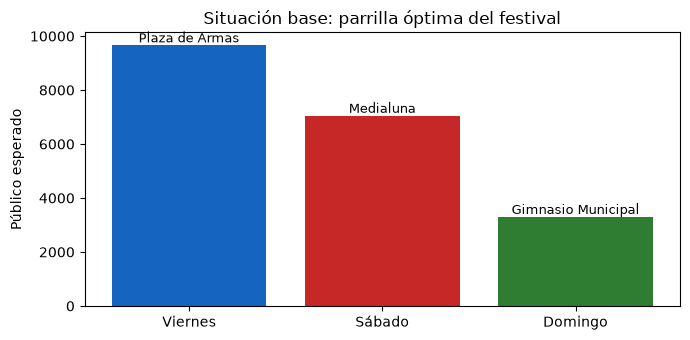

Costo total del festival: 249 MM$


In [22]:
# Preparamos la parrilla en el formato requerido.
parrilla_optima = [
    (
        alt["noche"],
        alt["recinto"],
        list(alt["terna"])
    )
    for alt in seleccionadas
]

# Visualizamos los resultados.
datos.mostrar_parrilla(
    parrilla_optima,
    titulo="Situación base: parrilla óptima del festival"
)

# La función oficial no incluye el costo de seguridad.
print("Costo total del festival:", costo_total_optimo, "MM$")

El gráfico muestra la distribución del público esperado durante las tres noches del festival. El viernes presenta la mayor asistencia, con 9.657 personas en la Plaza de Armas, seguido del sábado con 7.045 personas en la Medialuna y el domingo con 3.297 personas en el Gimnasio Municipal.

Estas diferencias se explican por las combinaciones de artistas seleccionadas, los factores de asistencia de cada noche y las capacidades de los recintos. La distribución obtenida permite alcanzar un público total de 19.999 personas, respetando las restricciones y el presupuesto disponible.

## Simulación de cancelaciones

Para evaluar la dependencia del festival respecto de cada artista, simularemos la cancelación individual de los tres artistas programados en cada noche. En cada escenario recalcularemos la demanda considerando únicamente los dos artistas restantes, manteniendo la noche y el recinto originalmente seleccionados.

Este análisis permitirá identificar cuánto público se perdería ante cada cancelación y determinar qué jornadas presentan mayor vulnerabilidad.

In [23]:
# Almacenamos los resultados de las cancelaciones.
resultados_cancelaciones = []

# Recorremos las tres noches de la solución óptima.
for alt in solucion_base["seleccionadas"]:

    noche = alt["noche"]
    recinto = alt["recinto"]
    artistas = alt["terna"]
    publico_original = alt["publico"]

    # Simulamos que cancela cada artista.
    for artista_cancelado in artistas:

        # Conservamos únicamente los dos artistas restantes.
        restantes = [
            artista for artista in artistas
            if artista != artista_cancelado
        ]

        # Recalculamos el público esperado.
        publico_restante = round(min(
            datos.FACTOR_NOCHE[noche] * datos.demanda(restantes),
            datos.RECINTOS[recinto]["capacidad"]
        ))

        # Calculamos la pérdida y la retención de público.
        perdida = publico_original - publico_restante
        retencion = 100 * publico_restante / publico_original

        resultados_cancelaciones.append({
            "Noche": noche,
            "Artista cancelado": artista_cancelado,
            "Público original": publico_original,
            "Público restante": publico_restante,
            "Pérdida de público": perdida,
            "Retención (%)": retencion
        })

# Construimos la tabla de resultados.
df_cancelaciones = pd.DataFrame(resultados_cancelaciones)

display(df_cancelaciones.round(2))

,Noche,Artista cancelado,Público original,Público restante,Pérdida de público,Retención (%)
0,Viernes,Kevo Flow,9657,3502,6155,36.26
1,Viernes,Los Cumbiancheros del Ñuble,9657,6741,2916,69.80
2,Viernes,Las Hermanas Quintral,9657,7390,2267,76.52
3,Sábado,Camila Arrebol,7045,1986,5059,28.19
4,Sábado,Grupo Tierra Sur,7045,5395,1650,76.58
5,Sábado,Niebla Austral,7045,5897,1148,83.70
6,Domingo,Ruta Cinco,3297,1544,1753,46.83
7,Domingo,Banda Fogata,3297,2405,892,72.95
8,Domingo,Tomás del Lago,3297,2445,852,74.16


Los resultados muestran que la cancelación de un artista puede afectar significativamente la asistencia del festival, especialmente cuando se trata de artistas con una alta capacidad de convocatoria.

El viernes presenta la mayor pérdida absoluta, con 6.155 asistentes menos ante la cancelación de Kevo Flow. Sin embargo, el sábado resulta ser la noche más vulnerable en términos porcentuales, ya que la ausencia de Camila Arrebol reduciría el público de 7.045 a 1.986 personas, conservando solamente el 28,19 % de la asistencia original.

Por otra parte, el domingo presenta una menor dependencia relativa, manteniendo al menos el 46,83 % del público ante cualquier cancelación individual.

Estos resultados evidencian la necesidad de evaluar nuevas condiciones que permitan reducir la dependencia de determinados artistas, manteniendo una asistencia competitiva y respetando el presupuesto disponible.

## Identificación de la noche más vulnerable

A partir de los escenarios de cancelación, identificaremos el caso más perjudicial para cada noche. Para ello, compararemos el porcentaje de público que permanecería después de la ausencia de un artista, ya que esta medida permite comparar jornadas con distintos niveles de asistencia.

,Noche,Artista cancelado,Público original,Público restante,Pérdida de público,Retención (%)
0,Viernes,Kevo Flow,9657,3502,6155,36.26
1,Sábado,Camila Arrebol,7045,1986,5059,28.19
2,Domingo,Ruta Cinco,3297,1544,1753,46.83


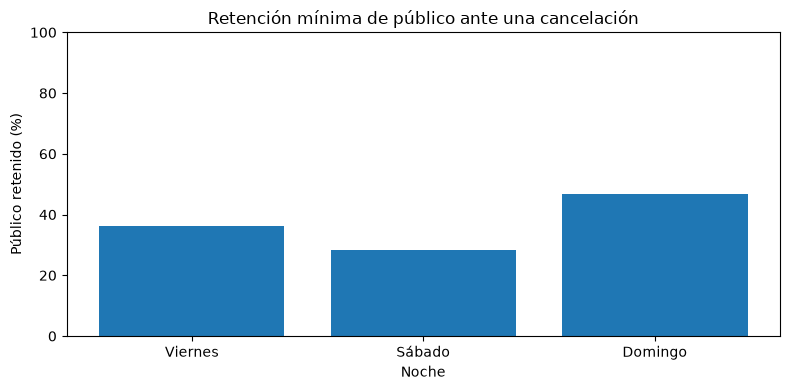

In [24]:
# Identificamos la cancelación más perjudicial de cada noche.
indices_criticos = df_cancelaciones.groupby("Noche")[
    "Retención (%)"
].idxmin()

df_vulnerabilidad = df_cancelaciones.loc[
    indices_criticos,
    [
        "Noche",
        "Artista cancelado",
        "Público original",
        "Público restante",
        "Pérdida de público",
        "Retención (%)"
    ]
].copy()

# Ordenamos las noches cronológicamente.
df_vulnerabilidad["Orden"] = df_vulnerabilidad[
    "Noche"
].map({
    noche: i for i, noche in enumerate(datos.NOCHES)
})

df_vulnerabilidad = (
    df_vulnerabilidad
    .sort_values("Orden")
    .drop(columns="Orden")
    .reset_index(drop=True)
)

display(df_vulnerabilidad.round(2))

# Visualizamos el porcentaje mínimo de retención por noche.
plt.figure(figsize=(8, 4))

plt.bar(
    df_vulnerabilidad["Noche"],
    df_vulnerabilidad["Retención (%)"]
)

plt.title("Retención mínima de público ante una cancelación")
plt.ylabel("Público retenido (%)")
plt.xlabel("Noche")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

El análisis permite identificar las noches más vulnerables ante la cancelación de un artista. El sábado presenta la menor retención de público, con un 28,19 % ante la ausencia de Camila Arrebol, seguido del viernes con un 36,26 % y el domingo con un 46,83 %.

Aunque el viernes presenta la mayor pérdida absoluta de asistentes, el sábado es la noche más perjudicada en términos porcentuales, ya que perdería más del 70 % de su público esperado.

Estos resultados evidencian una dependencia importante de determinados artistas, por lo que resulta conveniente incorporar nuevas condiciones al modelo que permitan garantizar una mayor retención de asistentes ante posibles cancelaciones.

## Preparación de las propuestas de mejora

Para reducir el impacto de las cancelaciones, propondremos condiciones que garanticen una asistencia mínima cuando falte cualquiera de los tres artistas de una noche.

Se evaluarán dos enfoques: exigir un porcentaje mínimo del público originalmente esperado y establecer un número mínimo de asistentes que deben permanecer ante cualquier cancelación.

Para incorporar ambas propuestas sin modificar la linealidad del modelo, calcularemos previamente el peor escenario de cancelación de cada alternativa disponible.

In [25]:
# Calculamos las cancelaciones de todas las alternativas.
for alt in alternativas:

    noche = alt["noche"]
    recinto = alt["recinto"]
    publico_original = alt["publico"]

    publicos_restantes = []

    # Evaluamos la cancelación de cada uno de los tres artistas.
    for artista_cancelado in alt["terna"]:

        artistas_restantes = [
            a for a in alt["terna"]
            if a != artista_cancelado
        ]

        publico_restante = round(min(
            datos.FACTOR_NOCHE[noche]
            * datos.demanda(artistas_restantes),
            datos.RECINTOS[recinto]["capacidad"]
        ))

        publicos_restantes.append(publico_restante)

    # Guardamos el peor escenario de la alternativa.
    alt["publico_minimo_cancelacion"] = min(publicos_restantes)

    # Calculamos la fracción mínima de público retenido.
    alt["retencion_minima"] = (
        min(publicos_restantes) / publico_original
        if publico_original > 0 else 0
    )

# Comprobamos que todas las alternativas fueron evaluadas.
assert all(
    "retencion_minima" in alt
    and "publico_minimo_cancelacion" in alt
    for alt in alternativas
)

print("Alternativas analizadas:", len(alternativas))

Alternativas analizadas: 3051


Se analizaron las 3.051 alternativas de programación del festival, calculando para cada una la asistencia mínima que se mantendría ante la cancelación individual de cualquiera de sus tres artistas.

Este procedimiento permite evaluar la vulnerabilidad de cada combinación y determinar cuáles cumplen distintos niveles de retención de público. Los resultados se utilizarán para incorporar nuevas restricciones al modelo, buscando reducir la dependencia de artistas individuales sin comprometer excesivamente la asistencia total ni el presupuesto disponible.

## Implementación de las propuestas de mejora en Gurobi

A partir del análisis de cancelaciones, incorporaremos nuevas condiciones al modelo de optimización para reducir la dependencia de artistas individuales. Se evaluarán dos enfoques: garantizar un porcentaje mínimo de público retenido y asegurar una cantidad mínima de asistentes ante cualquier cancelación.

Para ello, utilizaremos los valores calculados anteriormente para cada alternativa de programación. Las nuevas restricciones se incorporarán al modelo original, manteniendo las condiciones de presupuesto, disponibilidad y contratación.

In [26]:
def agregar_condiciones_cancelacion(
    modelo, x, retencion=None, minimo_personas=None
):

    # Agregamos las condiciones para cada noche.
    for j, noche in enumerate(datos.NOCHES):

        indices = indices_por_noche[noche]

        # Propuesta A: garantizar un porcentaje de retención.
        if retencion is not None:

            modelo.addConstr(
                gp.quicksum(
                    (
                        alternativas[i]["publico_minimo_cancelacion"]
                        - retencion * alternativas[i]["publico"]
                    ) * x[i]
                    for i in indices
                ) >= 0,
                name=f"retencion_{j}"
            )

        # Propuesta B: garantizar un número mínimo de asistentes.
        if minimo_personas is not None:

            modelo.addConstr(
                gp.quicksum(
                    alternativas[i]["publico_minimo_cancelacion"] * x[i]
                    for i in indices
                ) >= minimo_personas,
                name=f"minimo_publico_{j}"
            )

Para comparar las propuestas de manera consistente, desarrollaremos una función que resuelva cada escenario considerando las nuevas restricciones.

Al igual que en la situación base, primero se maximizará el público total esperado y posteriormente se minimizará el costo, manteniendo el máximo de asistencia obtenido. Así podremos realizar una comparación justa entre las distintas alternativas.

In [27]:
def resolver_propuesta(nombre, retencion=None, minimo_personas=None):

    # Primera optimización: maximizar el público.
    modelo_1, x_1, s_1, z_1, c_1 = construir_modelo(
        presupuesto=datos.PRESUPUESTO
    )

    # Incorporamos la condición de protección.
    agregar_condiciones_cancelacion(
        modelo_1, x_1, retencion, minimo_personas
    )

    modelo_1.Params.MIPGap = 0
    modelo_1.Params.OutputFlag = 0
    modelo_1.optimize()

    # Verificamos la optimalidad.
    if modelo_1.Status != GRB.OPTIMAL:
        print(f"{nombre}: no se obtuvo una solución óptima.")
        return None

    mejor_publico = int(round(z_1.getValue()))

    # Segunda optimización: minimizar el costo.
    modelo_2, x_2, s_2, z_2, c_2 = construir_modelo(
        presupuesto=datos.PRESUPUESTO
    )

    # Incorporamos nuevamente las condiciones de protección.
    agregar_condiciones_cancelacion(
        modelo_2, x_2, retencion, minimo_personas
    )

    # Mantenemos la asistencia máxima.
    modelo_2.addConstr(
        z_2 == mejor_publico,
        name="fijar_publico"
    )

    # Minimizamos el costo total.
    modelo_2.setObjective(c_2, GRB.MINIMIZE)

    modelo_2.Params.MIPGap = 0
    modelo_2.Params.OutputFlag = 0
    modelo_2.optimize()

    if modelo_2.Status != GRB.OPTIMAL:
        print(f"{nombre}: no se obtuvo un desempate óptimo.")
        return None

    # Recuperamos las alternativas seleccionadas.
    seleccionadas_propuesta = [
        alt for alt in alternativas
        if x_2[alt["id"]].X > 0.5
    ]

    seleccionadas_propuesta.sort(
        key=lambda alt: datos.NOCHES.index(alt["noche"])
    )

    # Guardamos los resultados.
    return {
        "nombre": nombre,
        "publico_total": mejor_publico,
        "costo_total": int(round(c_2.getValue())),
        "seguridad": s_2.X > 0.5,
        "seleccionadas": seleccionadas_propuesta
    }

Las funciones desarrolladas permiten incorporar condiciones adicionales de protección y resolver automáticamente los nuevos modelos de optimización.

Cada propuesta mantiene las restricciones originales del festival y utiliza el mismo procedimiento de resolución aplicado en la situación base. Esto permitirá comparar sus efectos sobre la asistencia esperada, los costos y la vulnerabilidad ante cancelaciones.

## Resolución y comparación de las propuestas

Una vez implementadas las nuevas restricciones, evaluaremos cuatro propuestas para determinar cómo afectan la programación del festival.

Las tres primeras exigirán porcentajes mínimos de retención de público de 40 %, 50 % y 60 %, respectivamente. La cuarta buscará garantizar al menos 2.500 asistentes por noche ante cualquier cancelación.

Posteriormente, compararemos los resultados con la situación base, considerando la asistencia total, el costo del festival, la pérdida de público y el nivel de protección alcanzado.

Resolver las cuatro propuestas

In [28]:
# Definimos los escenarios de protección.
propuestas = [
    {"nombre": "A1 - Retención 40 %", "retencion": 0.40},
    {"nombre": "A2 - Retención 50 %", "retencion": 0.50},
    {"nombre": "A3 - Retención 60 %", "retencion": 0.60},
    {"nombre": "B - Mínimo 2.500", "minimo_personas": 2500}
]

# Resolvemos cada propuesta utilizando Gurobi.
resultados_propuestas = {}

for propuesta in propuestas:

    resultado = resolver_propuesta(**propuesta)

    if resultado is not None:
        resultados_propuestas[propuesta["nombre"]] = resultado

# Incorporamos la situación base para comparar.
soluciones_comparadas = [
    {"nombre": "Situación base", **solucion_base},
    *resultados_propuestas.values()
]

Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0


Tabla comparativa

In [29]:
# Construimos una tabla con los indicadores principales.
resumen = []

for sol in soluciones_comparadas:

    escogidas = sol["seleccionadas"]

    resumen.append({
        "Escenario": sol["nombre"],
        "Público total": sol["publico_total"],
        "Costo (MM$)": sol["costo_total"],
        "Público perdido": (
            solucion_base["publico_total"] - sol["publico_total"]
        ),
        "Retención mínima (%)": round(
            100 * min(
                alt["retencion_minima"] for alt in escogidas
            ), 2
        ),
        "Mínimo tras cancelar": min(
            alt["publico_minimo_cancelacion"]
            for alt in escogidas
        )
    })

df_comparacion = pd.DataFrame(resumen)

display(df_comparacion)

,Escenario,Público total,Costo (MM$),Público perdido,Retención mínima (%),Mínimo tras cancelar
0,Situación base,19999,249,0,28.19,1544
1,A1 - Retención 40 %,19998,247,1,40.52,1544
2,A2 - Retención 50 %,19265,250,734,50.65,1688
3,A3 - Retención 60 %,17979,244,2020,60.89,1255
4,B - Mínimo 2.500,19998,247,1,37.53,2599


Comparación de las parrillas

In [30]:
# Construimos una tabla detallada por propuesta y noche.
detalles = []

for sol in soluciones_comparadas:

    for alt in sol["seleccionadas"]:

        detalles.append({
            "Escenario": sol["nombre"],
            "Noche": alt["noche"],
            "Recinto": alt["recinto"],
            "Artistas": ", ".join(alt["terna"]),
            "Público": alt["publico"],
            "Costo noche (MM$)": alt["costo"],
            "Retención mínima (%)": round(
                100 * alt["retencion_minima"], 2
            )
        })

df_detalle_propuestas = pd.DataFrame(detalles)

display(df_detalle_propuestas)

,Escenario,Noche,Recinto,Artistas,Público,Costo noche (MM$),Retención mínima (%)
0,Situación base,Viernes,Plaza de Armas,"Kevo Flow, Los Cumbiancheros del Ñuble, Las He...",9657,123,36.26
1,Situación base,Sábado,Medialuna,"Camila Arrebol, Grupo Tierra Sur, Niebla Austral",7045,87,28.19
2,Situación base,Domingo,Gimnasio Municipal,"Ruta Cinco, Banda Fogata, Tomás del Lago",3297,39,46.83
3,A1 - Retención 40 %,Viernes,Medialuna,"Los Volcanes, Los Cumbiancheros del Ñuble, Las...",7500,93,46.69
4,A1 - Retención 40 %,Sábado,Plaza de Armas,"Camila Arrebol, La Nena Real, Ruta Cinco",9841,116,40.52
5,A1 - Retención 40 %,Domingo,Gimnasio Municipal,"Grupo Tierra Sur, Banda Fogata, Tomás del Lago",2657,38,58.11
6,A2 - Retención 50 %,Viernes,Gimnasio Municipal,"La Nena Real, Ruta Cinco, Las Cantoras de Peum...",3980,50,52.26
7,A2 - Retención 50 %,Sábado,Plaza de Armas,"Camila Arrebol, Kevo Flow, Los Cumbiancheros d...",11952,154,57.71
8,A2 - Retención 50 %,Domingo,Gimnasio Municipal,"Grupo Tierra Sur, Las Hermanas Quintral, Niebl...",3333,46,50.65
9,A3 - Retención 60 %,Viernes,Medialuna,"Los Cumbiancheros del Ñuble, Las Hermanas Quin...",5451,69,62.85


Visualización de los resultados

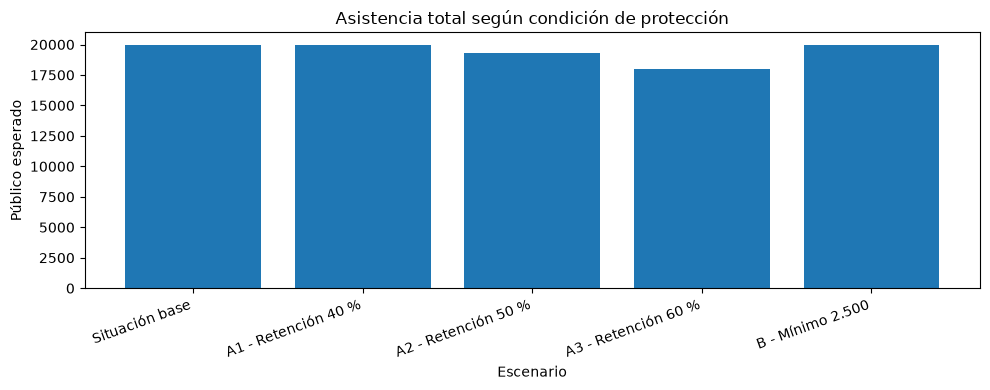

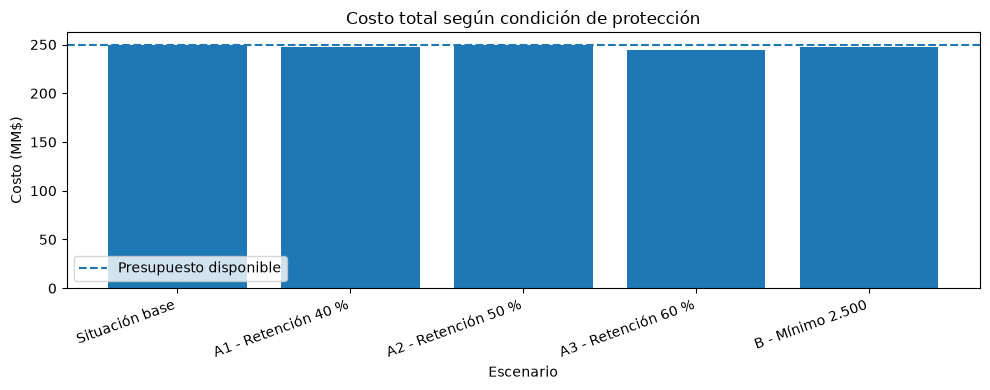

In [31]:
# Gráfico 1: público total por escenario.
plt.figure(figsize=(10, 4))

plt.bar(
    df_comparacion["Escenario"],
    df_comparacion["Público total"]
)

plt.title("Asistencia total según condición de protección")
plt.xlabel("Escenario")
plt.ylabel("Público esperado")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# Gráfico 2: costo total por escenario.
plt.figure(figsize=(10, 4))

plt.bar(
    df_comparacion["Escenario"],
    df_comparacion["Costo (MM$)"]
)

plt.axhline(
    datos.PRESUPUESTO,
    linestyle="--",
    label="Presupuesto disponible"
)

plt.title("Costo total según condición de protección")
plt.xlabel("Escenario")
plt.ylabel("Costo (MM$)")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

Los resultados muestran que las condiciones de protección ante cancelaciones permiten reducir la dependencia de artistas individuales, aunque su nivel de exigencia influye en la asistencia total y en la distribución del público entre las noches.

La propuesta A1 presenta resultados favorables, ya que incrementa la retención mínima del 28,19 % al 40,52 %, perdiendo solamente un asistente respecto de la situación base. Además, disminuye el costo total de 249 a 247 MM$.

Por otra parte, las propuestas A2 y A3 ofrecen mayores niveles de retención, pero generan pérdidas de 734 y 2.020 asistentes, respectivamente. Esto demuestra que aumentar las exigencias de protección puede reducir considerablemente la convocatoria máxima del festival.

La propuesta B también alcanza 19.998 asistentes con un costo de 247 MM$, pero garantiza un mínimo de 2.599 personas ante cualquier cancelación, superando el mínimo absoluto de la propuesta A1, aunque con una menor retención porcentual.

Finalmente, la comparación de las parrillas demuestra que las nuevas restricciones modifican tanto la selección de artistas como la distribución de recintos y asistentes. Por lo tanto, las propuestas A1 y B representan las alternativas más convenientes, dependiendo de si la municipalidad prioriza la retención proporcional o la cantidad mínima de público garantizado.

## Recomendación final

A partir de los resultados obtenidos, se recomienda implementar la propuesta A1, que exige mantener al menos el 40 % del público ante la cancelación de cualquier artista.

Esta alternativa aumenta la retención mínima desde el 28,19 % hasta el 40,52 %, manteniendo prácticamente la misma asistencia total, con una pérdida de solo un asistente. Además, reduce el costo del festival de 249 a 247 MM$.

Si bien la propuesta B garantiza una mayor cantidad mínima de asistentes ante cancelaciones, A1 ofrece una mejor protección proporcional en todas las noches. Por otra parte, las propuestas A2 y A3 generan pérdidas considerablemente mayores de público.

Por lo tanto, se considera que A1 ofrece el mejor equilibrio entre asistencia esperada, costo y reducción de la dependencia proporcional de artistas individuales.

## Análisis de diferentes presupuestos

Para evaluar cómo influye el presupuesto en la programación del festival, resolveremos el modelo original considerando cinco presupuestos diferentes: 180, 220, 260, 300 y 340 MM$.

En cada escenario se maximizará la asistencia total esperada y posteriormente se seleccionará la solución de menor costo entre aquellas que alcancen el máximo público. Esto permitirá comparar la distribución de artistas, recintos y asistentes, además de identificar cuándo es necesario contratar el plan de seguridad.

Función para resolver escenarios presupuestarios

In [32]:
# Incorporamos una condición de asistencia mínima en una noche.
def agregar_minimo_noche(modelo, x, noche, minimo):

    modelo.addConstr(
        gp.quicksum(
            alternativas[i]["publico"] * x[i]
            for i in indices_por_noche[noche]
        ) >= minimo,
        name="minimo_noche"
    )


def resolver_escenario(presupuesto, noche_objetivo=None, minimo_noche=None):

    # PRIMERA OPTIMIZACIÓN: maximizar la asistencia.
    modelo_1, x_1, s_1, z_1, c_1 = construir_modelo(
        presupuesto=presupuesto
    )

    # Incorporamos una condición adicional si corresponde.
    if minimo_noche is not None:
        agregar_minimo_noche(
            modelo_1, x_1, noche_objetivo, minimo_noche
        )

    modelo_1.Params.MIPGap = 0
    modelo_1.Params.OutputFlag = 0
    modelo_1.optimize()

    if modelo_1.Status != GRB.OPTIMAL:
        print("Sin óptimo comprobado. Estado:", modelo_1.Status)
        return None

    publico_maximo = int(round(z_1.getValue()))

    # SEGUNDA OPTIMIZACIÓN: minimizar el costo.
    modelo_2, x_2, s_2, z_2, c_2 = construir_modelo(
        presupuesto=presupuesto
    )

    if minimo_noche is not None:
        agregar_minimo_noche(
            modelo_2, x_2, noche_objetivo, minimo_noche
        )

    # Mantenemos el público máximo.
    modelo_2.addConstr(
        z_2 == publico_maximo,
        name="mantener_publico"
    )

    modelo_2.setObjective(c_2, GRB.MINIMIZE)

    modelo_2.Params.MIPGap = 0
    modelo_2.Params.OutputFlag = 0
    modelo_2.optimize()

    if modelo_2.Status != GRB.OPTIMAL:
        print("Sin desempate óptimo. Estado:", modelo_2.Status)
        return None

    # Recuperamos las alternativas seleccionadas.
    escogidas = [
        alt for alt in alternativas
        if x_2[alt["id"]].X > 0.5
    ]

    escogidas.sort(
        key=lambda a: datos.NOCHES.index(a["noche"])
    )

    return {
        "presupuesto": presupuesto,
        "publico_total": publico_maximo,
        "costo_total": int(round(c_2.getValue())),
        "seguridad": s_2.X > 0.5,
        "seleccionadas": escogidas
    }

Ejecutar los cinco presupuestos

In [33]:
# Presupuestos exigidos por el enunciado.
presupuestos = [180, 220, 260, 300, 340]

# Conservamos también el escenario base de 250 MM$.
todos_presupuestos = sorted(
    presupuestos + [datos.PRESUPUESTO]
)

resultados_presupuestos = {}

for presupuesto in todos_presupuestos:

    print(f"Resolviendo presupuesto de {presupuesto} MM$")

    # Reutilizamos la solución base ya calculada.
    if presupuesto == datos.PRESUPUESTO:
        resultado = solucion_base
    else:
        resultado = resolver_escenario(presupuesto)

    if resultado is not None:
        resultados_presupuestos[presupuesto] = resultado

Resolviendo presupuesto de 180 MM$
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Resolviendo presupuesto de 220 MM$
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Resolviendo presupuesto de 250 MM$
Resolviendo presupuesto de 260 MM$
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Resolviendo presupuesto de 300 MM$
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Resolviendo presupuesto de 340 MM$
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0


Tabla comparativa

In [34]:
filas_presupuestos = []

for presupuesto, resultado in sorted(
    resultados_presupuestos.items()
):

    # Identificamos la alternativa de cada noche.
    por_noche = {
        alt["noche"]: alt
        for alt in resultado["seleccionadas"]
    }

    fila = {
        "Presupuesto": presupuesto,
        "Público total": resultado["publico_total"],
        "Costo total": resultado["costo_total"],
        "Seguridad": "Sí" if resultado["seguridad"] else "No"
    }

    # Incorporamos público y recinto de cada noche.
    for noche in datos.NOCHES:
        fila[f"Público {noche}"] = por_noche[noche]["publico"]
        fila[f"Recinto {noche}"] = por_noche[noche]["recinto"]

    filas_presupuestos.append(fila)

df_presupuestos = pd.DataFrame(filas_presupuestos)

display(df_presupuestos)

,Presupuesto,Público total,Costo total,Seguridad,Público Viernes,Recinto Viernes,Público Sábado,Recinto Sábado,Público Domingo,Recinto Domingo
0,180,15384,180,No,3853,Gimnasio Municipal,7454,Medialuna,4077,Gimnasio Municipal
1,220,18632,220,No,7005,Medialuna,7500,Medialuna,4127,Gimnasio Municipal
2,250,19999,249,No,9657,Plaza de Armas,7045,Medialuna,3297,Gimnasio Municipal
3,260,20000,252,No,7153,Medialuna,9514,Plaza de Armas,3333,Gimnasio Municipal
4,300,22350,297,Sí,7350,Medialuna,7500,Medialuna,7500,Medialuna
5,340,25255,332,Sí,7252,Medialuna,10730,Plaza de Armas,7273,Medialuna


Gráficos comparativos

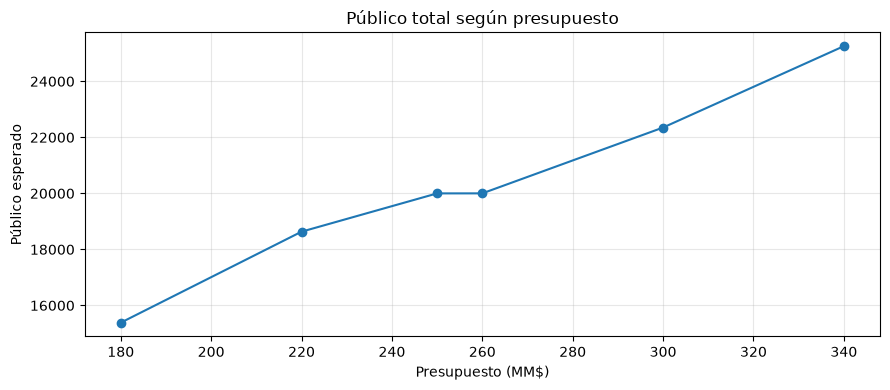

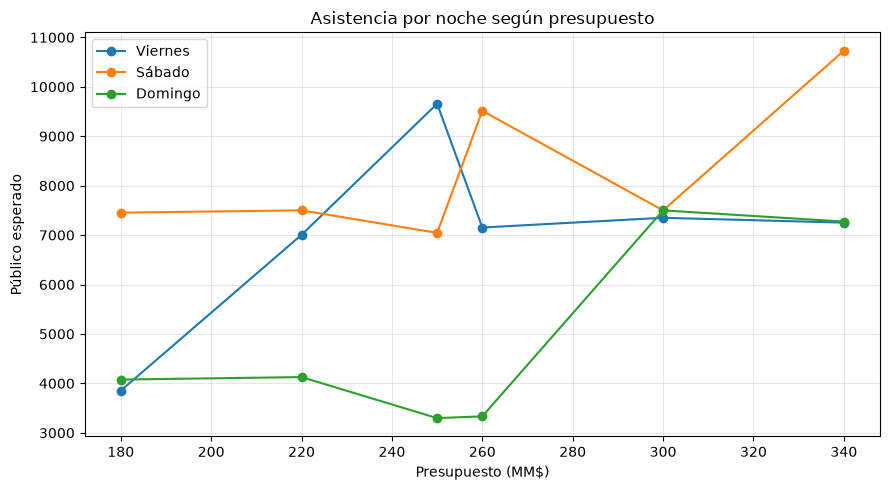

In [35]:
# Gráfico 1: público total según presupuesto.
plt.figure(figsize=(9, 4))

plt.plot(
    df_presupuestos["Presupuesto"],
    df_presupuestos["Público total"],
    marker="o"
)

plt.title("Público total según presupuesto")
plt.xlabel("Presupuesto (MM$)")
plt.ylabel("Público esperado")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfico 2: distribución por noche.
plt.figure(figsize=(9, 5))

for noche in datos.NOCHES:
    plt.plot(
        df_presupuestos["Presupuesto"],
        df_presupuestos[f"Público {noche}"],
        marker="o",
        label=noche
    )

plt.title("Asistencia por noche según presupuesto")
plt.xlabel("Presupuesto (MM$)")
plt.ylabel("Público esperado")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Los resultados muestran que el aumento del presupuesto permite incrementar la asistencia total esperada del festival, pasando de 15.384 personas con 180 MM$ a 25.255 personas con 340 MM$.

Sin embargo, este crecimiento no es proporcional, debido a que las decisiones de contratación y selección de recintos son discretas. Además, el presupuesto adicional no necesariamente mejora la asistencia de todas las noches, ya que el modelo prioriza maximizar el público total del festival.

Un ejemplo de esto ocurre al aumentar el presupuesto de 250 a 260 MM$, donde la asistencia total aumenta solamente en una persona, mientras que el público se redistribuye entre las tres jornadas.

Por otra parte, con un presupuesto de 260 MM$ se alcanzan exactamente 20.000 asistentes sin requerir el plan de seguridad. En cambio, con presupuestos de 300 y 340 MM$ se supera dicho umbral, por lo que es obligatorio incorporar su costo.

En consecuencia, los resultados evidencian que la relación entre presupuesto y asistencia depende de las combinaciones de artistas, los factores de cada noche, las capacidades de los recintos y las restricciones del modelo.

## Identificación de la noche más perjudicada

Para determinar qué noche resulta más perjudicada ante las reducciones presupuestarias, compararemos la asistencia de cada jornada con la situación base de 250 MM$.

Se calculará la variación absoluta y porcentual de público para los escenarios de 180 y 220 MM$. Esto permitirá identificar qué noche experimenta la mayor pérdida de asistentes y explicar el resultado a partir de la formulación del modelo.

In [36]:
# Recuperamos la asistencia de cada noche en la situación base.
base_por_noche = {
    alt["noche"]: alt["publico"]
    for alt in solucion_base["seleccionadas"]
}

filas_cambios = []

# Analizamos los dos presupuestos inferiores al original.
for presupuesto in [180, 220]:

    resultado = resultados_presupuestos[presupuesto]

    actual_por_noche = {
        alt["noche"]: alt["publico"]
        for alt in resultado["seleccionadas"]
    }

    for noche in datos.NOCHES:

        publico_base = base_por_noche[noche]
        publico_actual = actual_por_noche[noche]

        filas_cambios.append({
            "Presupuesto": presupuesto,
            "Noche": noche,
            "Público base": publico_base,
            "Público escenario": publico_actual,
            "Pérdida de público": publico_base - publico_actual,
            "Variación (%)": round(
                100 * (publico_actual - publico_base) / publico_base,
                2
            )
        })

# Mostramos la tabla comparativa.
df_cambios = pd.DataFrame(filas_cambios)
display(df_cambios)

# Identificamos la mayor pérdida absoluta.
mayor_perdida = df_cambios.loc[
    df_cambios["Pérdida de público"].idxmax()
]

noche_critica = mayor_perdida["Noche"]

print("Noche más perjudicada:", noche_critica)
print("Mayor pérdida:", mayor_perdida["Pérdida de público"])

,Presupuesto,Noche,Público base,Público escenario,Pérdida de público,Variación (%)
0,180,Viernes,9657,3853,5804,-60.10
1,180,Sábado,7045,7454,-409,5.81
2,180,Domingo,3297,4077,-780,23.66
3,220,Viernes,9657,7005,2652,-27.46
4,220,Sábado,7045,7500,-455,6.46
5,220,Domingo,3297,4127,-830,25.17


Noche más perjudicada: Viernes
Mayor pérdida: 5804


El análisis permite identificar que el viernes es la noche más perjudicada ante las reducciones presupuestarias. Con un presupuesto de 180 MM$, su asistencia disminuye de 9.657 a 3.853 personas, representando una pérdida del 60,10 %. Por otra parte, con 220 MM$, la asistencia se reduce a 7.005 personas, equivalente a una disminución del 27,46 %.

En contraste, el sábado y domingo presentan aumentos de público respecto de la situación base. Esto ocurre porque el modelo busca maximizar la asistencia total del festival, sin establecer una cantidad mínima de asistentes por noche.

Por lo tanto, al reducirse el presupuesto, el optimizador redistribuye artistas y recintos para obtener la mayor convocatoria conjunta posible, aunque esto perjudique considerablemente al viernes.

A partir de estos resultados, se propone incorporar nuevas condiciones que permitan mejorar la asistencia del viernes sin aumentar el presupuesto original de 250 MM$.

## Propuestas de mejora con 250 MM$

Una vez identificada la noche más perjudicada, incorporaremos condiciones adicionales que permitan mejorar su asistencia sin aumentar el presupuesto original de 250 MM$.

Para ello, evaluaremos dos niveles de asistencia mínima para el viernes: 9.700 y 10.500 personas. Posteriormente, resolveremos nuevamente el modelo y compararemos los resultados con la situación base, considerando el público esperado en cada noche, la asistencia total y los costos.

In [37]:
# Definimos las propuestas de mejora.
propuestas_mejora = [
    {
        "Escenario": "Piso de 9.700",
        "Exigencia": 9700
    },
    {
        "Escenario": "Piso de 10.500",
        "Exigencia": 10500
    }
]

# Incorporamos la situación base.
resultados_mejora = {
    "Situación base": solucion_base
}

# Resolvemos las nuevas propuestas.
for propuesta in propuestas_mejora:

    resultado = resolver_escenario(
        presupuesto=datos.PRESUPUESTO,
        noche_objetivo=noche_critica,
        minimo_noche=propuesta["Exigencia"]
    )

    if resultado is not None:
        resultados_mejora[propuesta["Escenario"]] = resultado


# Construimos una tabla comparativa.
filas_mejora = []

for nombre, resultado in resultados_mejora.items():

    por_noche = {
        alt["noche"]: alt
        for alt in resultado["seleccionadas"]
    }

    fila = {
        "Escenario": nombre,
        "Público total": resultado["publico_total"],
        "Costo (MM$)": resultado["costo_total"],
        "Pérdida total": (
            solucion_base["publico_total"]
            - resultado["publico_total"]
        )
    }

    # Incorporamos asistencia y recinto de cada noche.
    for noche in datos.NOCHES:
        fila[noche] = por_noche[noche]["publico"]
        fila[f"Recinto {noche}"] = por_noche[noche]["recinto"]

    fila["Mejora noche crítica"] = (
        por_noche[noche_critica]["publico"]
        - base_por_noche[noche_critica]
    )

    filas_mejora.append(fila)

df_mejora = pd.DataFrame(filas_mejora)
display(df_mejora)

Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0


,Escenario,Público total,Costo (MM$),Pérdida total,Viernes,Recinto Viernes,Sábado,Recinto Sábado,Domingo,Recinto Domingo,Mejora noche crítica
0,Situación base,19999,249,0,9657,Plaza de Armas,7045,Medialuna,3297,Gimnasio Municipal,0
1,Piso de 9.700,18798,246,1201,10756,Plaza de Armas,3878,Gimnasio Municipal,4164,Gimnasio Municipal,1099
2,Piso de 10.500,18798,246,1201,10756,Plaza de Armas,3878,Gimnasio Municipal,4164,Gimnasio Municipal,1099


Gráfico comparativo

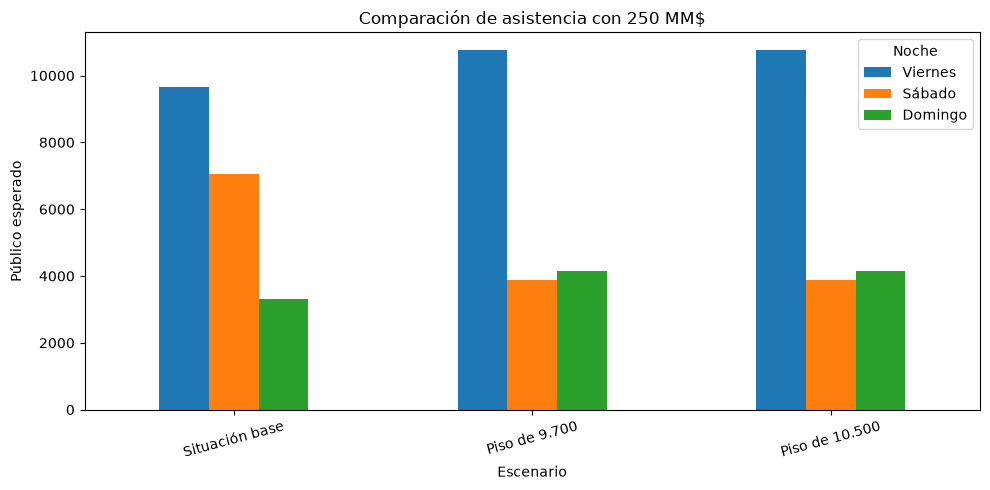

In [38]:
# Preparamos los datos para graficar.
df_grafico_mejora = df_mejora.set_index(
    "Escenario"
)[datos.NOCHES]

# Graficamos la asistencia por noche.
df_grafico_mejora.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparación de asistencia con 250 MM$")
plt.xlabel("Escenario")
plt.ylabel("Público esperado")
plt.xticks(rotation=15)
plt.legend(title="Noche")
plt.tight_layout()
plt.show()

Los resultados muestran que incorporar una asistencia mínima para el viernes permite mejorar su convocatoria de 9.657 a 10.756 personas, representando un aumento de 1.099 asistentes.

Sin embargo, esta modificación afecta la distribución del público entre las tres noches. El sábado disminuye su asistencia de 7.045 a 3.878 personas, mientras que el domingo aumenta de 3.297 a 4.164 asistentes.

Como consecuencia, el público total se reduce de 19.999 a 18.798 personas, equivalente a una pérdida de 1.201 asistentes. Por otra parte, el costo disminuye de 249 a 246 MM$, respetando el presupuesto disponible.

Ambas propuestas generan la misma solución óptima debido a la naturaleza discreta del modelo, donde un aumento en el nivel de exigencia no necesariamente produce cambios graduales en la programación.

Por lo tanto, aunque es posible mejorar la asistencia del viernes sin aumentar el presupuesto, esta mejora implica sacrificar parte de la convocatoria total y perjudicar especialmente al sábado.

## Análisis de sensibilidad

Para evaluar el efecto de las nuevas condiciones, modificaremos progresivamente el nivel mínimo de asistencia exigido para la noche más perjudicada.

En primer lugar, resolveremos cada escenario manteniendo el presupuesto de 250 MM$, con el objetivo de determinar la pérdida de público total.

Posteriormente, construiremos un modelo que minimice el costo necesario para mantener al menos la asistencia de la situación base, respetando la nueva exigencia. Esto permitirá determinar el presupuesto adicional necesario y recomendar un nivel de asistencia que considere tanto la distribución del público como los recursos disponibles.

Función para calcular el presupuesto necesario

In [39]:
# Calculamos una cota superior suficiente del presupuesto.
# Como se presentan nueve artistas distintos, utilizamos
# los nueve mayores costos posibles de contratación.

numero_contratos = 3 * len(datos.NOCHES)

mayores_costos_artistas = sorted(
    [
        info["costo"]
        for info in datos.ARTISTAS.values()
    ],
    reverse=True
)[:numero_contratos]

presupuesto_cota_superior = (
    sum(mayores_costos_artistas)
    + len(datos.NOCHES) * max(
        info["costo"]
        for info in datos.RECINTOS.values()
    )
    + datos.COSTO_SEGURIDAD
)


def costo_minimo_sin_perder_publico(noche, minimo):

    # Construimos el modelo con una cota suficiente de presupuesto.
    modelo, x, seguridad, publico_total, costo_total = construir_modelo(
        presupuesto=presupuesto_cota_superior
    )

    # Exigimos el público mínimo de la noche crítica.
    agregar_minimo_noche(
        modelo, x, noche, minimo
    )

    # Garantizamos mantener el público total de la situación base.
    modelo.addConstr(
        publico_total >= solucion_base["publico_total"],
        name="mantener_publico_base"
    )

    # Minimizamos el costo total del festival.
    modelo.setObjective(
        costo_total,
        GRB.MINIMIZE
    )

    modelo.Params.MIPGap = 0
    modelo.Params.OutputFlag = 0
    modelo.optimize()

    # Comprobamos la optimalidad.
    if modelo.Status != GRB.OPTIMAL:
        print("Sin óptimo comprobado:", modelo.Status)
        return None

    return int(round(costo_total.getValue()))

Ejecutar el análisis de sensibilidad

In [40]:
# Público actual de la noche crítica.
nivel_base = base_por_noche[noche_critica]

# Mayor asistencia posible de esa noche.
nivel_maximo_posible = max(
    alt["publico"]
    for alt in alternativas
    if alt["noche"] == noche_critica
)

# Definimos los niveles que analizaremos.
niveles_exigencia = sorted(set([
    nivel_base,
    nivel_base + 1,
    9700,
    9800,
    10000,
    10366,
    10500,
    nivel_maximo_posible
]))

filas_sensibilidad = []

for nivel in niveles_exigencia:

    print(f"Analizando exigencia de {nivel} personas")

    # Verificamos si el nivel es físicamente posible.
    if nivel > nivel_maximo_posible:
        continue

    # Resolvemos con el presupuesto original.
    if nivel <= nivel_base:
        escenario = solucion_base
    else:
        escenario = resolver_escenario(
            presupuesto=datos.PRESUPUESTO,
            noche_objetivo=noche_critica,
            minimo_noche=nivel
        )

    # Calculamos el presupuesto mínimo para no perder público.
    presupuesto_necesario = costo_minimo_sin_perder_publico(
        noche_critica,
        nivel
    )

    filas_sensibilidad.append({
        "Exigencia": nivel,
        "Público con 250 MM$": (
            escenario["publico_total"] if escenario else None
        ),
        "Pérdida de público": (
            solucion_base["publico_total"] - escenario["publico_total"]
            if escenario else None
        ),
        "Presupuesto mínimo sin pérdida": presupuesto_necesario,
        "Presupuesto adicional": (
            max(0, presupuesto_necesario - datos.PRESUPUESTO)
            if presupuesto_necesario is not None else None
        )
    })

df_sensibilidad = pd.DataFrame(filas_sensibilidad)

display(df_sensibilidad)

Analizando exigencia de 9657 personas
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Analizando exigencia de 9658 personas
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Analizando exigencia de 9700 personas
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Analizando exigencia de 9800 personas
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Analizando exigencia de 10000 personas
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set parameter MIPGap to value 0
Set param

,Exigencia,Público con 250 MM$,Pérdida de público,Presupuesto mínimo sin pérdida,Presupuesto adicional
0,9657,19999,0,249,0
1,9658,18798,1201,268,18
2,9700,18798,1201,268,18
3,9800,18798,1201,268,18
4,10000,18798,1201,268,18
5,10366,18798,1201,268,18
6,10500,18798,1201,268,18
7,10756,18798,1201,268,18


Gráficos de sensibilidad

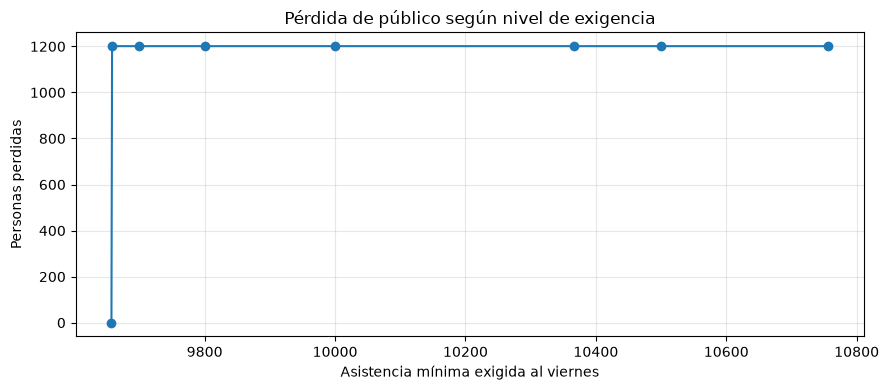

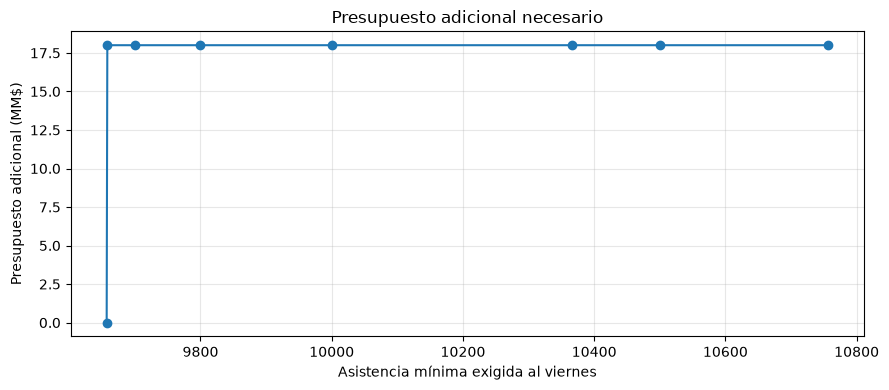

In [41]:
# Gráfico 1: pérdida de público.
plt.figure(figsize=(9, 4))

plt.plot(
    df_sensibilidad["Exigencia"],
    df_sensibilidad["Pérdida de público"],
    marker="o"
)

plt.title("Pérdida de público según nivel de exigencia")
plt.xlabel("Asistencia mínima exigida al viernes")
plt.ylabel("Personas perdidas")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfico 2: presupuesto adicional.
plt.figure(figsize=(9, 4))

plt.plot(
    df_sensibilidad["Exigencia"],
    df_sensibilidad["Presupuesto adicional"],
    marker="o"
)

plt.title("Presupuesto adicional necesario")
plt.xlabel("Asistencia mínima exigida al viernes")
plt.ylabel("Presupuesto adicional (MM$)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El análisis de sensibilidad demuestra que aumentar el nivel mínimo de asistencia exigido para el viernes genera cambios discretos en la solución óptima, debido a que las combinaciones de artistas y recintos no pueden seleccionarse parcialmente.

Al exigir una asistencia superior a las 9.657 personas de la situación base, el público total disminuye de 19.999 a 18.798 asistentes, representando una pérdida de 1.201 personas. Este resultado se mantiene para los niveles analizados hasta alcanzar una exigencia de 10.756 asistentes, correspondiente a la máxima convocatoria posible del viernes.

Por otra parte, para cumplir estas exigencias sin reducir el público total original, se requiere un presupuesto mínimo de 268 MM$, equivalente a 18 MM$ adicionales respecto de los recursos inicialmente disponibles.

Por lo tanto, mejorar la asistencia del viernes implica un costo de oportunidad significativo. La municipalidad deberá decidir si prioriza mantener la convocatoria total con el presupuesto original o destinar recursos adicionales para mejorar la distribución del público entre las jornadas.

## Recomendación final

A partir del análisis presupuestario, se determinó que el viernes es la noche más perjudicada ante las reducciones del presupuesto, debido a que el modelo prioriza la maximización del público total sin garantizar una asistencia mínima por jornada.

Para mejorar esta situación, se propone establecer una exigencia mínima de 10.000 asistentes para el viernes. Con el presupuesto original de 250 MM$, esta condición permite aumentar la convocatoria de dicha noche a 10.756 personas, aunque reduce la asistencia total del festival a 18.798 personas.

El análisis de sensibilidad demuestra que, para implementar esta condición sin perder los 19.999 asistentes de la situación base, sería necesario disponer de un presupuesto mínimo de 268 MM$, equivalente a 18 MM$ adicionales.

Por lo tanto, si la municipalidad dispone de mayores recursos y considera prioritario fortalecer la asistencia del viernes, se recomienda implementar esta exigencia junto con el aumento presupuestario señalado. En cambio, si debe mantenerse estrictamente el presupuesto de 250 MM$ y se prioriza maximizar la convocatoria total, resulta más conveniente conservar la programación original.

Finalmente, los resultados evidencian la importancia de considerar tanto la eficiencia global como la distribución de asistentes entre las noches al tomar decisiones de programación del festival.